# Ensemble Methods: Bagging, Boosting, and Voting

A complete guide: intuition, mathematics, and implementation from scratch.

**Prerequisites:** decision trees (see `1_decision_tree.ipynb`)

## Table of Contents

1. [Why Ensembles?](#why-ensembles)
2. [The Bias-Variance Tradeoff](#bias-variance)
3. [Setup & Imports](#imports)
4. [Bagging (Bootstrap Aggregating)](#bagging)
   - [Bootstrap Sampling](#bootstrap)
   - [Variance Reduction: Math Proof](#variance-reduction)
5. [Random Forest](#random-forest)
   - [Algorithm & Implementation](#rf-implementation)
   - [Out-of-Bag (OOB) Error](#oob)
   - [Demo: Breast Cancer Dataset](#rf-demo)
6. [Boosting: General Idea](#boosting)
7. [AdaBoost](#adaboost)
   - [Algorithm & Implementation](#adaboost-impl)
   - [Visualizing \u03b1 and \u03b5](#adaboost-viz)
8. [Gradient Boosting](#gradient-boosting)
   - [Algorithm & Implementation](#gb-impl)
   - [Learning Rate vs. n_estimators](#gb-lr)
9. [XGBoost: Key Innovations](#xgboost)
10. [Voting Ensembles](#voting)
    - [Hard & Soft Voting Implementation](#voting-impl)
    - [Weighted Voting](#weighted-voting)
11. [Stacking (Meta-Learning)](#stacking)
12. [Comprehensive Comparison](#comparison)
13. [Feature Importance in Random Forest](#feature-importance)
14. [Summary](#summary)
15. [Sources](#sources)

<a id="why-ensembles"></a>
## 1. Why Ensembles? The Wisdom of Crowds

A single decision tree has a critical weakness: **high variance**. Small changes in training data produce completely different trees. A deep tree memorizes noise; a shallow tree misses structure.

**Key insight:** If we train many independent classifiers that each make different errors, combining their predictions tends to cancel out individual errors.

**Analogy \u2014 exam grading:** One teacher grading 100 exams might be inconsistent (high variance). Twenty teachers grading the same exam and averaging their scores produces a far more reliable result.

### Two orthogonal strategies

| Strategy | Key idea | Main algorithms |
|---|---|---|
| **Bagging** | Train many models **in parallel** on random data subsets; average predictions | Random Forest |
| **Boosting** | Train models **sequentially**, each correcting the errors of the previous | AdaBoost, Gradient Boosting, XGBoost |
| **Voting/Stacking** | Combine **different model types** via voting or a meta-learner | VotingClassifier, Stacking |

To understand *why* these work, we first need the **bias-variance tradeoff**.

<a id="bias-variance"></a>
## 2. The Bias-Variance Tradeoff

For any model, the expected prediction error on unseen data can be decomposed as:

$$\mathbb{E}[(y - \hat{f}(x))^2] = \underbrace{\text{Bias}[\hat{f}(x)]^2}_{\text{systematic error}} + \underbrace{\text{Var}[\hat{f}(x)]}_{\text{sensitivity to data}} + \underbrace{\sigma^2}_{\text{irreducible noise}}$$

Where:
- **Bias** $= \mathbb{E}[\hat{f}(x)] - f(x)$ \u2014 how far off the average prediction is from truth
- **Variance** $= \mathbb{E}[(\hat{f}(x) - \mathbb{E}[\hat{f}(x)])^2]$ \u2014 how much predictions vary across different training sets
- **$\sigma^2$** \u2014 noise in the data itself, cannot be reduced

### Where each ensemble method helps

| Method | Fixes | Mechanism |
|---|---|---|
| **Bagging** | High **variance** | Averaging uncorrelated models reduces variance: $\text{Var}(\bar{X}) = \sigma^2/n$ |
| **Boosting** | High **bias** | Sequential correction pushes toward the true function |
| **Voting** | Both (depending on base learners) | Diversity of model types reduces error from multiple angles |

<a id="imports"></a>
## 3. Setup & Imports

Import all libraries used throughout this notebook: NumPy and Matplotlib for numerics and visualization, scikit-learn for datasets and reference implementations, and standard Python utilities.

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.datasets import load_breast_cancer, make_classification, load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestClassifier, AdaBoostClassifier,
    GradientBoostingClassifier, VotingClassifier
)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

np.random.seed(42)
print("Imports OK")

Imports OK


<a id="bagging"></a>
## 4. Part I \u2014 Bagging (Bootstrap Aggregating)

### 4.1 Intuition

Bagging, introduced by Breiman (1996), exploits a statistical fact:

> The variance of the **average** of $n$ i.i.d. random variables is $\sigma^2 / n$.

If we could train $n$ models on $n$ independent datasets and average them, variance would vanish. But we have only **one** dataset.

**Bootstrap sampling** solves this: we simulate $n$ independent datasets by sampling *with replacement* from the original data. Each bootstrap sample is a valid approximation of the true data distribution.

### 4.2 Bootstrap Sampling

<a id="bootstrap"></a>

Given dataset $D = \{(x_1, y_1), \ldots, (x_n, y_n)\}$, a bootstrap sample $D^*$ is formed by drawing $n$ samples **with replacement**.

**Key property:** On average, a bootstrap sample contains $\approx 63.2\%$ of the original samples (some are repeated, some are left out). The probability that a specific sample is NOT selected in any of the $n$ draws:

$$P(\text{not selected}) = \left(1 - \frac{1}{n}\right)^n \xrightarrow{n \to \infty} e^{-1} \approx 0.368$$

The leftover $\approx 36.8\%$ are called **Out-of-Bag (OOB)** samples \u2014 they act as a free validation set!

### 4.3 The Bagging Algorithm

```
for b in 1 ... B:
    D_b = bootstrap_sample(D)          # sample n points with replacement
    h_b = train_base_learner(D_b)      # train model on the bootstrap sample

# Prediction (classification):
predict(x) = majority_vote( h_1(x), h_2(x), ..., h_B(x) )

# Prediction (regression):
predict(x) = (1/B) * sum( h_b(x) for b in 1..B )
```

Define the `bootstrap_sample` helper function that draws $n$ samples with replacement and returns the selected data together with a boolean mask marking the out-of-bag (OOB) samples.

In [26]:
def bootstrap_sample(X, y, random_state=None):
    """
    Draw n samples with replacement from (X, y).
    Returns (X_boot, y_boot, oob_mask) where oob_mask marks samples NOT selected.
    """
    rng = np.random.RandomState(random_state)
    n = len(y)
    indices    = rng.choice(n, size=n, replace=True)
    oob_mask   = np.ones(n, dtype=bool)
    oob_mask[indices] = False
    return X[indices], y[indices], oob_mask

Empirically verify the theoretical $\approx 63.2\%$ coverage claim by running 500 bootstrap trials on a dummy dataset and averaging the fraction of unique samples selected.

In [27]:
# Verify the ~63.2% coverage empirically
n = 1000
X_dummy = np.arange(n).reshape(-1, 1)
y_dummy = np.zeros(n)

coverage_rates = []
for trial in range(500):
    _, _, oob = bootstrap_sample(X_dummy, y_dummy, random_state=trial)
    coverage_rates.append(1 - oob.mean())   # fraction of samples selected

print(f"Empirical coverage: {np.mean(coverage_rates):.4f}  (theoretical: {1 - np.exp(-1):.4f})")
print(f"OOB fraction:       {1 - np.mean(coverage_rates):.4f}  (theoretical: {np.exp(-1):.4f} = e\u207b\u00b9)")

Empirical coverage: 0.6324  (theoretical: 0.6321)
OOB fraction:       0.3676  (theoretical: 0.3679 = e⁻¹)


<a id="variance-reduction"></a>
### 4.4 Variance Reduction: Mathematical Proof

Suppose we have $B$ models $h_1, \ldots, h_B$, each with variance $\sigma^2$ and pairwise correlation $\rho$. The variance of their average is:

$$\text{Var}\left(\frac{1}{B}\sum_{b=1}^B h_b\right) = \rho \sigma^2 + \frac{1 - \rho}{B} \sigma^2$$

**Two observations:**
1. As $B \to \infty$, the second term vanishes \u2192 the irreducible floor is $\rho \sigma^2$
2. To minimize the floor, we need **low correlation $\rho$** between models

This is why bagging works best when base learners are **diverse** (low $\rho$). High-variance models like deep trees are perfect base learners for bagging.

Plot the ensemble variance formula $\rho\sigma^2 + (1-\rho)\sigma^2/B$ for several values of $\rho$ to show how inter-tree correlation sets a floor on the variance reduction achievable by adding more trees.

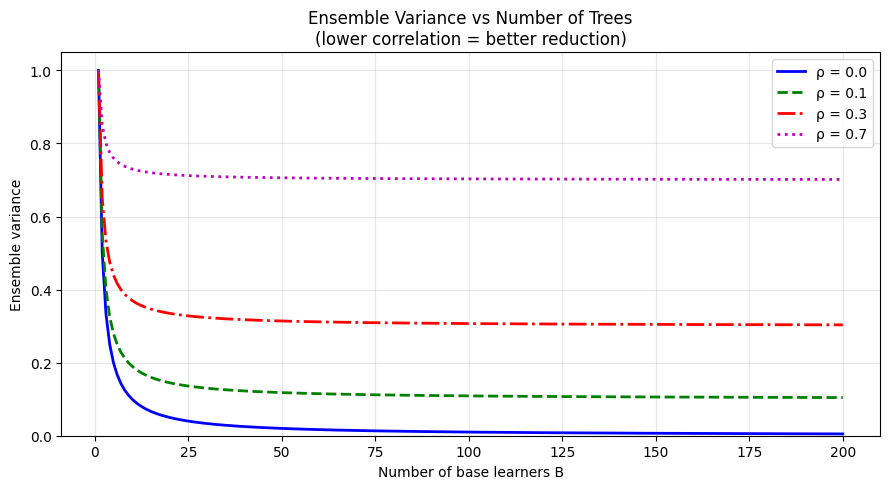

In [28]:
# Visualize variance reduction formula: rho*sigma^2 + (1-rho)*sigma^2/B
sigma2 = 1.0
B_range = np.arange(1, 201)

plt.figure(figsize=(9, 5))
for rho, style in [(0.0, 'b-'), (0.1, 'g--'), (0.3, 'r-.'), (0.7, 'm:')]:
    var = rho * sigma2 + (1 - rho) * sigma2 / B_range
    plt.plot(B_range, var, style, linewidth=2, label=f'\u03c1 = {rho}')

plt.xlabel('Number of base learners B')
plt.ylabel('Ensemble variance')
plt.title('Ensemble Variance vs Number of Trees\n(lower correlation = better reduction)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

<a id="random-forest"></a>
## 5. Random Forest

### 5.1 Intuition

Random Forest (Breiman, 2001) is bagging applied to decision trees, with one crucial modification:

> At each split, instead of searching all $p$ features, only a **random subset of $m$ features** is considered.

**Why?** Consider a dataset with one very strong predictor. Every bootstrapped tree will use that feature at the root \u2014 the trees become highly correlated ($\rho \approx 1$), and bagging helps little.

By randomly restricting which features are available at each split, trees are forced to find *different* patterns in the data \u2192 lower $\rho$ \u2192 much better variance reduction.

### 5.2 Algorithm

```
Hyperparameters: B (n_estimators), m (max_features), max_depth

Training:
    for b = 1 ... B:
        D_b = bootstrap_sample(D)
        h_b = decision_tree with modification:
              at each node, only sample m features from p total

Prediction:
    classify: majority_vote( h_b(x) for b=1..B )
    regress:  mean( h_b(x) for b=1..B )
```

### 5.3 Choosing `max_features` ($m$)

Typical defaults:
- Classification: $m = \lfloor \sqrt{p} \rfloor$
- Regression: $m = \lfloor p/3 \rfloor$

These are heuristics from empirical studies. $m$ controls the bias-variance tradeoff:
- **Large $m$ (close to $p$)**: trees are stronger but correlated \u2192 less variance reduction
- **Small $m$**: trees are weaker but more diverse \u2192 better variance reduction, but more bias

<a id="rf-implementation"></a>
### 5.4 Algorithm & Implementation

Implement `RandomForest` from scratch: for each of the $B$ trees, draw a bootstrap sample, then train a `DecisionTreeClassifier` that randomly considers only $m = \lfloor\sqrt{p}\rfloor$ features at each split. Prediction uses majority vote across all trees.

In [29]:
class RandomForest:
    """
    Random Forest classifier from scratch.
    
    Parameters
    ----------
    n_estimators : int   \u2014 number of trees
    max_features : int or 'sqrt'  \u2014 features to consider at each split
    max_depth    : int or None
    min_samples_split : int
    """

    def __init__(self, n_estimators=100, max_features='sqrt',
                 max_depth=None, min_samples_split=2, random_state=42):
        self.n_estimators     = n_estimators
        self.max_features     = max_features
        self.max_depth        = max_depth
        self.min_samples_split = min_samples_split
        self.random_state     = random_state
        self.trees_           = []   # list of fitted DecisionTreeClassifier
        self.oob_scores_      = []

    def fit(self, X, y):
        n, p = X.shape
        m = int(np.sqrt(p)) if self.max_features == 'sqrt' else self.max_features

        rng = np.random.RandomState(self.random_state)
        self.trees_ = []

        for b in range(self.n_estimators):
            # 1. Bootstrap sample
            idx    = rng.choice(n, size=n, replace=True)
            X_boot = X[idx]
            y_boot = y[idx]

            # 2. Train a decision tree with random feature subsampling
            #    sklearn's DecisionTreeClassifier accepts max_features directly
            tree = DecisionTreeClassifier(
                max_depth=self.max_depth,
                min_samples_split=self.min_samples_split,
                max_features=m,
                random_state=rng.randint(0, 10_000)
            )
            tree.fit(X_boot, y_boot)
            self.trees_.append(tree)

        return self

    def predict(self, X):
        """Majority vote across all trees."""
        # Shape: (n_estimators, n_samples)
        all_preds = np.array([tree.predict(X) for tree in self.trees_])
        # For each sample, pick the most common prediction
        return np.array([
            Counter(all_preds[:, i]).most_common(1)[0][0]
            for i in range(X.shape[0])
        ])

    def predict_proba(self, X):
        """Average class probabilities across all trees (soft voting)."""
        all_proba = np.array([tree.predict_proba(X) for tree in self.trees_])
        return all_proba.mean(axis=0)


print("RandomForest class defined.")

RandomForest class defined.


<a id="oob"></a>
### 5.5 Out-of-Bag (OOB) Error

Because each tree is trained on $\approx 63.2\%$ of samples, the remaining $\approx 36.8\%$ (OOB samples) can be used as a validation set **for free** — no separate hold-out needed.

For each training sample $i$, predict using only the trees that did **not** see sample $i$ during training:

$$\hat{y}_i^{\text{OOB}} = \text{majority\_vote}\left(\{h_b(x_i) : b \in \{1,\ldots,B\},\, i \notin D_b\}\right)$$

OOB error is the average misclassification rate across all $\hat{y}_i^{\text{OOB}}$. It is an unbiased estimate of the generalization error.

Extend `RandomForest` to track which samples are OOB for each tree, accumulate their out-of-bag predictions, and compute `oob_score_` as the accuracy of those predictions against the true labels.

In [30]:
class RandomForestWithOOB(RandomForest):
    """Extends RandomForest to track OOB indices and compute OOB accuracy."""

    def fit(self, X, y):
        n, p = X.shape
        m    = int(np.sqrt(p)) if self.max_features == 'sqrt' else self.max_features
        rng  = np.random.RandomState(self.random_state)

        self.trees_       = []
        self.oob_indices_ = []  # which samples are OOB for each tree

        for b in range(self.n_estimators):
            idx      = rng.choice(n, size=n, replace=True)
            oob_mask = np.ones(n, dtype=bool)
            oob_mask[idx] = False

            tree = DecisionTreeClassifier(
                max_depth=self.max_depth,
                min_samples_split=self.min_samples_split,
                max_features=m,
                random_state=rng.randint(0, 10_000)
            )
            tree.fit(X[idx], y[idx])
            self.trees_.append(tree)
            self.oob_indices_.append(np.where(oob_mask)[0])

        # Compute OOB predictions using list-of-lists to avoid sentinel collision
        oob_preds_list = [[] for _ in range(n)]
        has_oob = np.zeros(n, dtype=bool)
        for tree, oob_idx in zip(self.trees_, self.oob_indices_):
            if len(oob_idx) > 0:
                preds = tree.predict(X[oob_idx])
                for i, pred in zip(oob_idx, preds):
                    oob_preds_list[i].append(pred)
                    has_oob[i] = True

        self.oob_prediction_ = np.array([
            Counter(lst).most_common(1)[0][0] if lst else None
            for lst in oob_preds_list
        ])

        valid = has_oob
        self.oob_score_ = accuracy_score(y[valid], self.oob_prediction_[valid].astype(int))
        return self


print("RandomForestWithOOB class defined.")

RandomForestWithOOB class defined.


<a id="rf-demo"></a>
### 5.6 Demo: Breast Cancer Dataset

Load the breast cancer dataset, fit our `RandomForestWithOOB` implementation alongside sklearn's `RandomForestClassifier` and a single decision tree, then compare test accuracy and OOB accuracy across all three.

In [31]:
# Demo: Random Forest on breast cancer dataset
cancer = load_breast_cancer()
X_c, y_c = cancer.data, cancer.target
X_tr, X_te, y_tr, y_te = train_test_split(X_c, y_c, test_size=0.2, random_state=42)

# Our implementation
rf = RandomForestWithOOB(n_estimators=100, max_depth=None, random_state=42)
rf.fit(X_tr, y_tr)
test_acc = accuracy_score(y_te, rf.predict(X_te))
print(f"Our RF  \u2014 Test accuracy: {test_acc:.4f}   OOB accuracy: {rf.oob_score_:.4f}")

# sklearn baseline
sk_rf = RandomForestClassifier(n_estimators=100, oob_score=True, random_state=42)
sk_rf.fit(X_tr, y_tr)
sk_acc = accuracy_score(y_te, sk_rf.predict(X_te))
print(f"sklearn \u2014 Test accuracy: {sk_acc:.4f}   OOB accuracy: {sk_rf.oob_score_:.4f}")

# Single tree baseline
single = DecisionTreeClassifier(random_state=42)
single.fit(X_tr, y_tr)
print(f"Single tree \u2014 Test accuracy: {accuracy_score(y_te, single.predict(X_te)):.4f}")

Our RF  — Test accuracy: 0.9649   OOB accuracy: 0.9670
sklearn — Test accuracy: 0.9649   OOB accuracy: 0.9560
Single tree — Test accuracy: 0.9474


Sweep the number of trees from 1 to 200 using sklearn's `RandomForestClassifier` (with `oob_score=True`) and plot both test accuracy and OOB accuracy to illustrate how the ensemble stabilizes as more trees are added.

/home/gmarcuccetti/Scaricati/Hands-On-Deep-Learning-Algorithms-with-Python-master/.venv/lib/python3.12/site-packages/sklearn/ensemble/_forest.py:611: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
/home/gmarcuccetti/Scaricati/Hands-On-Deep-Learning-Algorithms-with-Python-master/.venv/lib/python3.12/site-packages/sklearn/ensemble/_forest.py:611: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
/home/gmarcuccetti/Scaricati/Hands-On-Deep-Learning-Algorithms-with-Python-master/.venv/lib/python3.12/site-packages/sklearn/ensemble/_forest.py:611: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


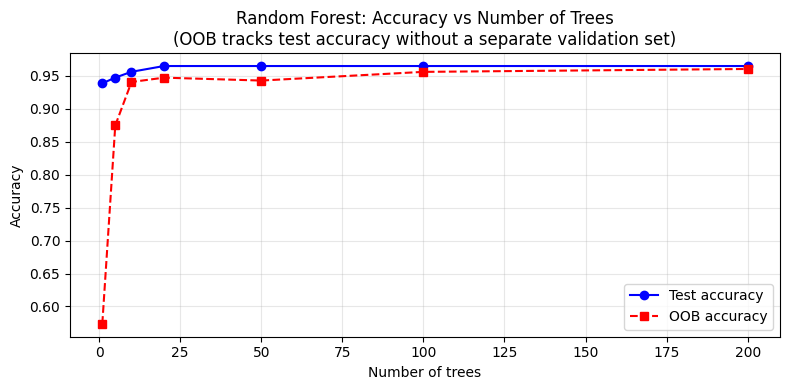

In [32]:
# Effect of n_estimators on accuracy and stability
n_trees_range = [1, 5, 10, 20, 50, 100, 200]
test_accs, oob_accs = [], []

for n_trees in n_trees_range:
    sk = RandomForestClassifier(n_estimators=n_trees, oob_score=True, random_state=42)
    sk.fit(X_tr, y_tr)
    test_accs.append(accuracy_score(y_te, sk.predict(X_te)))
    oob_accs.append(sk.oob_score_)

plt.figure(figsize=(8, 4))
plt.plot(n_trees_range, test_accs, 'b-o', label='Test accuracy')
plt.plot(n_trees_range, oob_accs,  'r--s', label='OOB accuracy')
plt.xlabel('Number of trees')
plt.ylabel('Accuracy')
plt.title('Random Forest: Accuracy vs Number of Trees\n(OOB tracks test accuracy without a separate validation set)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

<a id="boosting"></a>
## 6. Part II \u2014 Boosting

### 6.1 The Boosting Idea

Boosting trains models **sequentially**. Each new model focuses on the samples the previous models got **wrong**.

**Key insight:** Even a *weak learner* (a model only slightly better than random) can be boosted into an arbitrarily accurate model through sequential correction.

This was a theoretical surprise (Schapire, 1990) \u2014 the **PAC learning theory** result that showed weak learnability implies strong learnability.

### 6.2 Boosting vs. Bagging

| | Bagging | Boosting |
|---|---|---|
| Training order | Parallel (independent) | Sequential (dependent) |
| Main target | Reduces **variance** | Reduces **bias** |
| Base learner | Deep trees (low bias, high variance) | Shallow trees / stumps (high bias, low variance) |
| Combination | Uniform average / majority vote | Weighted average |
| Overfitting risk | Low | Higher (but self-regularizing in some methods) |

<a id="adaboost"></a>
## 7. AdaBoost (Adaptive Boosting)

### 7.1 Intuition

AdaBoost (Freund & Schapire, 1997) maintains a **weight** for each training sample. Initially all weights are equal. After each round:
- Misclassified samples get **higher weight** → next model focuses on them
- Correctly classified samples get **lower weight**

Final prediction: weighted majority vote of all models (better models get more say).

### 7.2 Algorithm

**Binary classification:** labels $y \in \{-1, +1\}$

**Initialization:** $w_i^{(1)} = 1/n$ for all samples $i$

**For each round $t = 1, \ldots, T$:**

1. Train weak learner $h_t$ on the **weighted** training set

2. Compute weighted error:
$$\epsilon_t = \sum_{i=1}^n w_i^{(t)} \cdot \mathbf{1}[h_t(x_i) \neq y_i]$$

   **The algorithm requires $\epsilon_t < 1/2$; it halts if this condition is not met.**

3. Compute learner weight (confidence of $h_t$):
$$\alpha_t = \frac{1}{2} \ln\left(\frac{1 - \epsilon_t}{\epsilon_t}\right)$$

   - If $\epsilon_t < 0.5$ (better than random): $\alpha_t > 0$ → positive influence
   - If $\epsilon_t = 0.5$ (random): $\alpha_t = 0$ → ignored

4. Update sample weights:
$$w_i^{(t+1)} = \frac{w_i^{(t)} \cdot \exp\left(-\alpha_t \cdot y_i \cdot h_t(x_i)\right)}{Z_t}$$

   where $Z_t = \sum_j w_j^{(t)} \exp\left(-\alpha_t \cdot y_j \cdot h_t(x_j)\right)$ is the normalization constant.

   - Correct prediction: $y_i \cdot h_t(x_i) = 1$ → weight decreases
   - Wrong prediction: $y_i \cdot h_t(x_i) = -1$ → weight increases

**Final prediction:**
$$H(x) = \text{sign}\left(\sum_{t=1}^T \alpha_t h_t(x)\right)$$

<a id="adaboost-impl"></a>
### 7.3 Algorithm & Implementation

Implement `AdaBoost` from scratch: maintain sample weights, train a weighted decision stump each round, compute $\alpha_t$ from the weighted error $\epsilon_t$, update and renormalize weights, then combine all stumps via a weighted sign vote.

In [33]:
class AdaBoost:
    """
    AdaBoost classifier from scratch (binary classification, labels {-1, +1}).

    Parameters
    ----------
    n_estimators : int
    max_depth    : int  — depth of each weak learner (1 = decision stump)
    random_state : int or None
    """

    def __init__(self, n_estimators=50, max_depth=1, random_state=None):
        self.n_estimators = n_estimators
        self.max_depth    = max_depth
        self.random_state = random_state

    def fit(self, X, y):
        """
        y must be in {-1, +1}.
        Internally converts {0, 1} → {-1, +1} if needed.
        """
        self.classes_ = np.unique(y)
        # Map to {-1, +1} if input is {0, 1}
        if set(self.classes_) == {0, 1}:
            y = 2 * y - 1

        n = len(y)
        weights = np.ones(n) / n   # uniform initialization
        rng = np.random.RandomState(self.random_state)

        self.estimators_ = []
        self.alphas_     = []
        self.errors_     = []

        for t in range(self.n_estimators):
            # 1. Train weak learner on weighted data
            stump = DecisionTreeClassifier(
                max_depth=self.max_depth,
                random_state=rng.randint(0, 10_000)
            )
            stump.fit(X, y, sample_weight=weights)

            # 2. Compute weighted error
            preds   = stump.predict(X)
            wrong   = (preds != y).astype(float)
            epsilon = np.dot(weights, wrong)

            # Halt if weak learner is no better than random
            if epsilon >= 0.5:
                break
            epsilon = np.clip(epsilon, 1e-10, 1 - 1e-10)

            # 3. Compute learner weight
            alpha = 0.5 * np.log((1 - epsilon) / epsilon)

            # 4. Update sample weights
            weights *= np.exp(-alpha * y * preds)
            weights /= weights.sum()   # normalize (= divide by Z_t)

            self.estimators_.append(stump)
            self.alphas_.append(alpha)
            self.errors_.append(epsilon)

        return self

    def predict(self, X):
        """Weighted vote, then map back to original class labels."""
        # Accumulate weighted votes
        scores = sum(
            alpha * estimator.predict(X)
            for alpha, estimator in zip(self.alphas_, self.estimators_)
        )
        raw = np.sign(scores)   # {-1, +1}
        # Map back to {0, 1} if original classes were {0, 1}
        if set(self.classes_) == {0, 1}:
            return ((raw + 1) / 2).astype(int)
        return raw.astype(int)


print("AdaBoost class defined.")

AdaBoost class defined.


Train our `AdaBoost` (100 stumps) on the breast cancer data and compare test accuracy against sklearn's `AdaBoostClassifier` to validate the scratch implementation.

In [34]:
# Demo AdaBoost
ada = AdaBoost(n_estimators=100, max_depth=1)
ada.fit(X_tr, y_tr)
ada_acc = accuracy_score(y_te, ada.predict(X_te))
print(f"Our AdaBoost (100 stumps) \u2014 Test accuracy: {ada_acc:.4f}")

sk_ada = AdaBoostClassifier(n_estimators=100, random_state=42)
sk_ada.fit(X_tr, y_tr)
print(f"sklearn AdaBoost          \u2014 Test accuracy: {accuracy_score(y_te, sk_ada.predict(X_te)):.4f}")

Our AdaBoost (100 stumps) — Test accuracy: 0.9737
sklearn AdaBoost          — Test accuracy: 0.9737


<a id="adaboost-viz"></a>
### 7.4 Visualizing \u03b1 and \u03b5

Plot how the weighted error $\epsilon_t$ and the learner weight $\alpha_t$ evolve across boosting rounds to show that early stumps achieve lower error and therefore receive higher weight in the final ensemble.

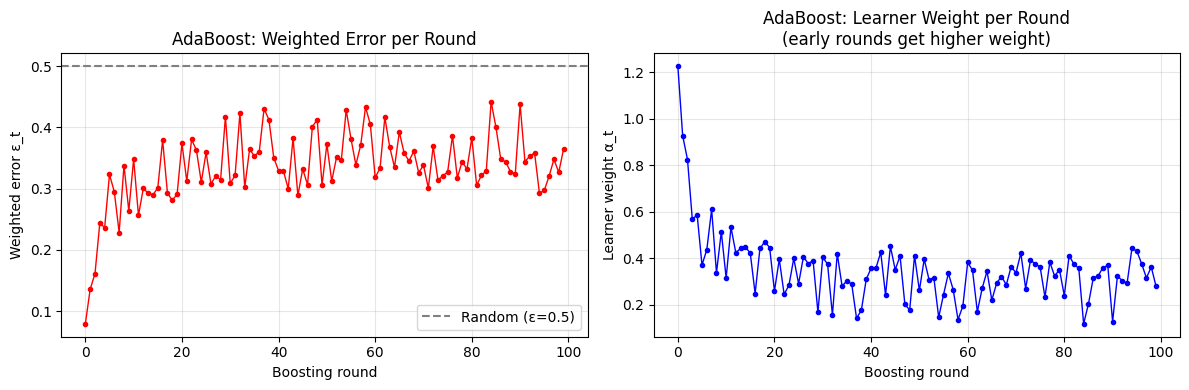

In [35]:
# Visualize how alpha and epsilon evolve across rounds
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(ada.errors_, 'r-o', markersize=3, linewidth=1)
axes[0].axhline(0.5, color='gray', linestyle='--', label='Random (\u03b5=0.5)')
axes[0].set_xlabel('Boosting round')
axes[0].set_ylabel('Weighted error \u03b5_t')
axes[0].set_title('AdaBoost: Weighted Error per Round')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(ada.alphas_, 'b-o', markersize=3, linewidth=1)
axes[1].set_xlabel('Boosting round')
axes[1].set_ylabel('Learner weight \u03b1_t')
axes[1].set_title('AdaBoost: Learner Weight per Round\n(early rounds get higher weight)')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

<a id="gradient-boosting"></a>
## 8. Gradient Boosting

### 8.1 Intuition

Gradient Boosting (Friedman, 2001) frames boosting as **gradient descent in function space**.

**Key insight:** Instead of reweighting samples (AdaBoost style), each new tree fits the **residuals** \u2014 the difference between current predictions and the true target.

Analogy: imagine building a prediction iteratively. First tree makes a rough guess. Second tree corrects the errors of the first. Third tree corrects the errors of the second. Each step gets us closer to the truth.

### 8.2 The Math: Gradient Descent in Function Space

We want to minimize a loss $L$ over the entire training set:

$$\mathcal{L} = \sum_{i=1}^n L(y_i, F(x_i))$$

where $F(x)$ is our current ensemble prediction. We build $F$ additively:

$$F_T(x) = F_0(x) + \sum_{t=1}^T \eta \cdot h_t(x)$$

**Gradient step:** The steepest descent direction in function space is the **negative gradient**:

$$r_i^{(t)} = -\left[\frac{\partial L(y_i, F(x_i))}{\partial F(x_i)}\right]_{F = F_{t-1}}$$

These $r_i^{(t)}$ are called **pseudo-residuals**. We fit a new tree $h_t$ to predict these residuals.

### 8.3 For Squared-Error Loss (Regression)

$$L(y, F) = \frac{1}{2}(y - F)^2 \implies r_i = -\frac{\partial L}{\partial F} = y_i - F(x_i)$$

For squared error, pseudo-residuals are simply the **true residuals**. This is why the algorithm is often described as "fit the residuals."

### 8.4 For Log-Loss (Classification)

Using binary log-loss with $p = \sigma(F(x))$:

$$L(y, F) = -[y \log p + (1-y)\log(1-p)]$$

$$r_i = y_i - p_i = y_i - \sigma(F_{t-1}(x_i))$$

Again, pseudo-residuals = actual residuals (probability prediction errors)!

### 8.5 Full Algorithm

```
F_0(x) = initial guess (e.g., log-odds of positive class)

for t = 1 ... T:
    r_i = -dL/dF evaluated at F_{t-1}(x_i)   \u2190 pseudo-residuals
    h_t = fit decision tree to (X, r)          \u2190 fit residuals
    F_t = F_{t-1} + \u03b7 * h_t                    \u2190 update (\u03b7 = learning rate)

predict(x) = F_T(x)
```

<a id="gb-impl"></a>
### 8.6 Algorithm & Implementation

Implement `GradientBoostingClassifier_scratch`: initialize with log-odds, then iteratively compute pseudo-residuals $(y - \sigma(F))$, fit a regression tree to them, and update the running prediction $F$ by the learning rate times the tree output.

In [36]:
def sigmoid(x):
    return np.where(x >= 0, 1 / (1 + np.exp(-x)), np.exp(x) / (1 + np.exp(x)))


class GradientBoostingClassifier_scratch:
    """
    Gradient Boosting classifier from scratch.
    Uses log-loss with pseudo-residuals = y - sigmoid(F).

    Parameters
    ----------
    n_estimators  : int
    learning_rate : float  — step size η (shrinkage)
    max_depth     : int    — depth of each tree
    """

    def __init__(self, n_estimators=100, learning_rate=0.1, max_depth=3):
        self.n_estimators  = n_estimators
        self.learning_rate = learning_rate
        self.max_depth     = max_depth

    def fit(self, X, y):
        n = len(y)

        # Initial prediction: log-odds of positive class
        p_mean  = np.clip(y.mean(), 1e-7, 1 - 1e-7)
        self.F0 = np.log(p_mean / (1 - p_mean))

        F = np.full(n, self.F0)   # current raw predictions (log-odds)

        self.trees_  = []
        self.residuals_history_ = []

        for t in range(self.n_estimators):
            # 1. Compute pseudo-residuals = negative gradient of log-loss
            probs    = sigmoid(F)
            residuals = y - probs
            self.residuals_history_.append(np.abs(residuals).mean())

            # 2. Fit a regression tree to pseudo-residuals
            tree = DecisionTreeRegressor(max_depth=self.max_depth)
            tree.fit(X, residuals)

            # 3. Update predictions
            F += self.learning_rate * tree.predict(X)

            self.trees_.append(tree)

        return self

    def predict_proba(self, X):
        F = np.full(X.shape[0], self.F0)
        for tree in self.trees_:
            F += self.learning_rate * tree.predict(X)
        p_pos = sigmoid(F)
        return np.column_stack([1 - p_pos, p_pos])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


print("GradientBoosting class defined.")

GradientBoosting class defined.


Train the scratch gradient boosting implementation (200 trees, lr=0.1, depth=3) on the breast cancer data and compare test accuracy against sklearn's `GradientBoostingClassifier` with the same hyperparameters.

In [37]:
# Demo Gradient Boosting
gb = GradientBoostingClassifier_scratch(n_estimators=200, learning_rate=0.1, max_depth=3)
gb.fit(X_tr, y_tr)
gb_acc = accuracy_score(y_te, gb.predict(X_te))
print(f"Our GradBoost (200 trees, lr=0.1) \u2014 Test accuracy: {gb_acc:.4f}")

sk_gb = GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, max_depth=3, random_state=42)
sk_gb.fit(X_tr, y_tr)
print(f"sklearn GradBoost                 \u2014 Test accuracy: {accuracy_score(y_te, sk_gb.predict(X_te)):.4f}")

Our GradBoost (200 trees, lr=0.1) — Test accuracy: 0.9561
sklearn GradBoost                 — Test accuracy: 0.9561


Plot the mean absolute pseudo-residual at each boosting round to confirm that successive trees progressively reduce the remaining prediction error.

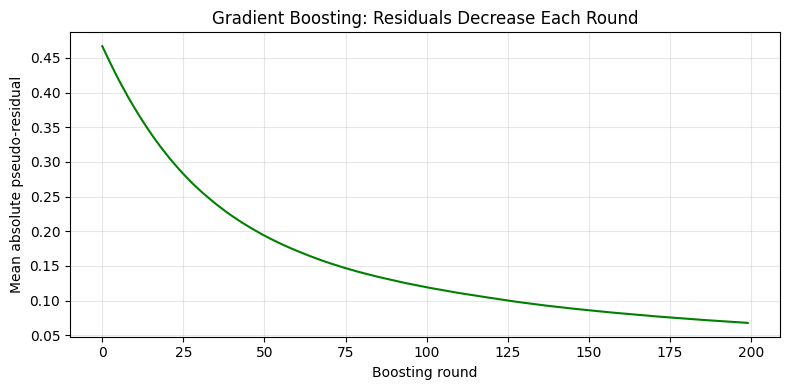

In [38]:
# Show how residuals decrease across rounds
plt.figure(figsize=(8, 4))
plt.plot(gb.residuals_history_, 'g-', linewidth=1.5)
plt.xlabel('Boosting round')
plt.ylabel('Mean absolute pseudo-residual')
plt.title('Gradient Boosting: Residuals Decrease Each Round')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

<a id="gb-lr"></a>
### 8.7 Learning Rate vs. n_estimators

The **learning rate** $\eta$ (also called *shrinkage*) scales the contribution of each tree:

$$F_t = F_{t-1} + \eta \cdot h_t$$

**Trade-off:**
- Small $\eta$ \u2192 smaller steps \u2192 need **more trees** but better generalization (less overfitting)
- Large $\eta$ \u2192 faster convergence \u2192 need **fewer trees** but more prone to overfitting

A key practical rule: **lower $\eta$, more trees** \u2192 usually better performance, at the cost of training time.

Sweep learning rate values on a log scale (fixing `n_estimators=200`) and plot test accuracy to visualize the optimal range and the degradation caused by values that are too small or too large.

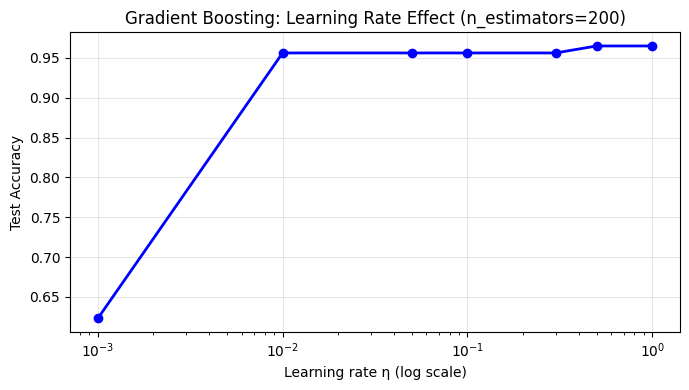

In [39]:
# Learning rate vs accuracy tradeoff
lr_values   = [0.001, 0.01, 0.05, 0.1, 0.3, 0.5, 1.0]
n_estimators_fixed = 200

lr_accs = []
for lr in lr_values:
    model = GradientBoostingClassifier(n_estimators=n_estimators_fixed, learning_rate=lr,
                                        max_depth=3, random_state=42)
    model.fit(X_tr, y_tr)
    lr_accs.append(accuracy_score(y_te, model.predict(X_te)))

plt.figure(figsize=(7, 4))
plt.semilogx(lr_values, lr_accs, 'b-o', linewidth=2)
plt.xlabel('Learning rate \u03b7 (log scale)')
plt.ylabel('Test Accuracy')
plt.title(f'Gradient Boosting: Learning Rate Effect (n_estimators={n_estimators_fixed})')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

<a id="xgboost"></a>
## 9. XGBoost: Key Innovations Over Gradient Boosting

XGBoost (Chen & Guestrin, 2016) is the dominant gradient boosting implementation. It introduces several key improvements:

### 9.1 Second-Order Taylor Expansion

Standard gradient boosting uses only the first-order gradient (slope). XGBoost uses both:

$$\mathcal{L}^{(t)} \approx \sum_{i=1}^n \left[ g_i f_t(x_i) + \frac{1}{2} h_i f_t(x_i)^2 \right] + \Omega(f_t)$$

where:
- $g_i = \partial_{F} L(y_i, F_{t-1}(x_i))$ — first-order gradient (same as pseudo-residuals)
- $h_i = \partial^2_{F} L(y_i, F_{t-1}(x_i))$ — second-order gradient (Hessian)

Using the Hessian gives better step size estimation → faster convergence.

### 9.2 Regularization Term

XGBoost adds an explicit regularization term to the objective:

$$\Omega(f) = \gamma T + \frac{1}{2} \lambda \sum_{j=1}^T w_j^2$$

where $T$ is number of leaves and $w_j$ are leaf scores. This penalizes complex trees directly.

### 9.3 Optimal Leaf Weights

By combining the Taylor expansion with the regularization term, XGBoost derives a **closed-form optimal weight** for each leaf:

$$w_j^* = -\frac{\sum_{i \in \text{leaf}_j} g_i}{\sum_{i \in \text{leaf}_j} h_i + \lambda}$$

And the gain formula for splitting becomes:

$$\text{Gain} = \frac{1}{2}\left[\frac{G_L^2}{H_L + \lambda} + \frac{G_R^2}{H_R + \lambda} - \frac{(G_L+G_R)^2}{H_L+H_R+\lambda}\right] - \gamma$$

where $G = \sum g_i$ and $H = \sum h_i$ for each side of the split.

### 9.4 Other XGBoost innovations

| Feature | Effect |
|---|---|
| Column subsampling | Like Random Forest — reduces correlation between trees |
| Row subsampling | Stochastic gradient boosting — faster, sometimes better |
| `max_delta_step` | Stabilizes updates for imbalanced datasets |
| Tree pruning | Grows tree fully then prunes (vs. greedy stop) |
| Weighted quantile sketch | Approximate split finding for large datasets |
| Sparsity-aware split | Handles missing values and sparse features natively |

Benchmark sklearn's `HistGradientBoostingClassifier` (which implements XGBoost-style second-order optimization and histogram binning) and, if the `xgboost` package is installed, the real XGBoost classifier.

In [40]:
# XGBoost demo using sklearn-compatible GradientBoostingClassifier
# (xgboost library optional \u2014 showing conceptual comparison)

from sklearn.ensemble import HistGradientBoostingClassifier  # sklearn's XGBoost-like impl

hgb = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1,
                                      max_depth=3, random_state=42)
hgb.fit(X_tr, y_tr)
print(f"HistGradientBoosting (sklearn, XGBoost-style) \u2014 Test: {accuracy_score(y_te, hgb.predict(X_te)):.4f}")

# Try importing real XGBoost if available
try:
    import xgboost as xgb
    xgb_model = xgb.XGBClassifier(n_estimators=200, learning_rate=0.1,
                                   max_depth=3, random_state=42,
                                   eval_metric='logloss', verbosity=0)
    xgb_model.fit(X_tr, y_tr)
    print(f"XGBoost                                       \u2014 Test: {accuracy_score(y_te, xgb_model.predict(X_te)):.4f}")
except ImportError:
    print("XGBoost not installed. Install with: pip install xgboost")

HistGradientBoosting (sklearn, XGBoost-style) — Test: 0.9649
XGBoost not installed. Install with: pip install xgboost


<a id="voting"></a>
## 10. Part III \u2014 Voting Ensembles

### 10.1 Intuition

Voting ensembles combine **heterogeneous** models \u2014 models of different types that make different kinds of errors. This exploits *model diversity* rather than data diversity (bagging) or sequential correction (boosting).

**Why do different model types help?**

A logistic regression is good at linear boundaries. A decision tree captures non-linear splits. A k-NN model is good locally. If they disagree, it is often because one is wrong for a specific reason \u2014 averaging over their errors helps.

### 10.2 Hard Voting

Each model votes for a class. The class with the most votes wins.

$$H(x) = \arg\max_k \sum_{j=1}^J \mathbf{1}[h_j(x) = k]$$

**Example:** Models predict [A, A, B]. Majority \u2192 A.

### 10.3 Soft Voting

Each model outputs class **probabilities**. Average the probabilities, then take the argmax.

$$H(x) = \arg\max_k \frac{1}{J} \sum_{j=1}^J p_j(y = k \mid x)$$

**Example:** Models output [0.7, 0.6, 0.4] for class A \u2192 average 0.567 \u2192 class A.

Soft voting is usually **better** than hard voting because it uses more information (the confidence of each prediction, not just the winner).

<a id="voting-impl"></a>
### 10.4 Hard & Soft Voting Implementation

Implement `VotingEnsemble` supporting both hard voting (weighted majority class) and soft voting (weighted average of `predict_proba` outputs), with an optional per-estimator weight vector.

In [41]:
class VotingEnsemble:
    """
    Voting ensemble from scratch.

    Parameters
    ----------
    estimators : list of (name, model) tuples
    voting     : 'hard' or 'soft'
    weights    : optional list of weights per estimator
    """

    def __init__(self, estimators, voting='hard', weights=None):
        self.estimators = estimators
        self.voting     = voting
        self.weights    = weights if weights else [1.0] * len(estimators)

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        for name, model in self.estimators:
            model.fit(X, y)
        return self

    def predict(self, X):
        if self.voting == 'hard':
            return self._hard_vote(X)
        else:
            return self._soft_vote(X)

    def _hard_vote(self, X):
        # Collect predictions from all models: shape (n_models, n_samples)
        all_preds = np.array([
            model.predict(X) for _, model in self.estimators
        ])
        # Weighted majority vote per sample
        n_samples = X.shape[0]
        result = np.empty(n_samples, dtype=all_preds.dtype)
        for i in range(n_samples):
            votes = {}
            for j, (_, _) in enumerate(self.estimators):
                cls = all_preds[j, i]
                votes[cls] = votes.get(cls, 0) + self.weights[j]
            result[i] = max(votes, key=votes.get)
        return result

    def _soft_vote(self, X):
        # Average weighted probabilities
        all_proba = np.array([
            w * model.predict_proba(X)
            for (_, model), w in zip(self.estimators, self.weights)
        ])   # shape: (n_models, n_samples, n_classes)
        avg_proba = all_proba.sum(axis=0) / sum(self.weights)
        return self.classes_[np.argmax(avg_proba, axis=1)]


print("VotingEnsemble class defined.")

VotingEnsemble class defined.


Evaluate each base model (decision tree, logistic regression, k-NN) individually, then combine them via our `VotingEnsemble` with both hard and soft voting, and cross-check against sklearn's `VotingClassifier`.

In [42]:
# Demo: combine a decision tree, logistic regression, and k-NN
base_models = [
    ('tree', DecisionTreeClassifier(max_depth=5, random_state=42)),
    ('lr',   LogisticRegression(max_iter=1000, random_state=42)),
    ('knn',  KNeighborsClassifier(n_neighbors=5)),
]

# Individual model performance
print("=== Individual models ===")
for name, model in base_models:
    model.fit(X_tr, y_tr)
    acc = accuracy_score(y_te, model.predict(X_te))
    print(f"  {name:6s}: {acc:.4f}")

print()

# Reset (VotingEnsemble will refit internally)
base_models = [
    ('tree', DecisionTreeClassifier(max_depth=5, random_state=42)),
    ('lr',   LogisticRegression(max_iter=1000, random_state=42)),
    ('knn',  KNeighborsClassifier(n_neighbors=5)),
]

print("=== Voting ensembles ===")
for voting in ['hard', 'soft']:
    ens = VotingEnsemble(base_models, voting=voting)
    ens.fit(X_tr, y_tr)
    acc = accuracy_score(y_te, ens.predict(X_te))
    print(f"  Our {voting} voting:    {acc:.4f}")

# sklearn VotingClassifier comparison
base_models_sk = [
    ('tree', DecisionTreeClassifier(max_depth=5, random_state=42)),
    ('lr',   LogisticRegression(max_iter=1000, random_state=42)),
    ('knn',  KNeighborsClassifier(n_neighbors=5)),
]

for voting in ['hard', 'soft']:
    sk_vc = VotingClassifier(estimators=base_models_sk, voting=voting)
    sk_vc.fit(X_tr, y_tr)
    acc = accuracy_score(y_te, sk_vc.predict(X_te))
    print(f"  sklearn {voting} voting: {acc:.4f}")

=== Individual models ===
  tree  : 0.9474
  lr    : 0.9561


/home/gmarcuccetti/Scaricati/Hands-On-Deep-Learning-Algorithms-with-Python-master/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


  knn   : 0.9561

=== Voting ensembles ===


/home/gmarcuccetti/Scaricati/Hands-On-Deep-Learning-Algorithms-with-Python-master/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/gmarcuccetti/Scaricati/Hands-On-Deep-Learning-Algorithms-with-Python-master/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the conve

  Our hard voting:    0.9649
  Our soft voting:    0.9737


/home/gmarcuccetti/Scaricati/Hands-On-Deep-Learning-Algorithms-with-Python-master/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


  sklearn hard voting: 0.9649
  sklearn soft voting: 0.9737


/home/gmarcuccetti/Scaricati/Hands-On-Deep-Learning-Algorithms-with-Python-master/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


<a id="weighted-voting"></a>
### 10.5 Weighted Voting

Not all models are equal. We can assign **weights** proportional to their validation accuracy:

$$H(x) = \arg\max_k \sum_{j=1}^J w_j \cdot p_j(y = k \mid x), \quad w_j \propto \text{val\_accuracy}_j$$

Better models get more influence in the final decision.

Estimate per-model weights via 5-fold cross-validation accuracy, then build a soft `VotingEnsemble` with those weights and compare its test accuracy against the uniform-weight version.

In [43]:
# Weighted soft voting: weight each model by its validation accuracy
from sklearn.model_selection import cross_val_score

base_models_w = [
    ('tree', DecisionTreeClassifier(max_depth=5, random_state=42)),
    ('lr',   LogisticRegression(max_iter=1000, random_state=42)),
    ('knn',  KNeighborsClassifier(n_neighbors=5)),
]

# Estimate weights via cross-validation
weights = []
print("Cross-validation accuracies (used as weights):")
for name, model in base_models_w:
    cv_score = cross_val_score(model, X_tr, y_tr, cv=5, scoring='accuracy').mean()
    weights.append(cv_score)
    print(f"  {name}: {cv_score:.4f}")

base_models_w2 = [
    ('tree', DecisionTreeClassifier(max_depth=5, random_state=42)),
    ('lr',   LogisticRegression(max_iter=1000, random_state=42)),
    ('knn',  KNeighborsClassifier(n_neighbors=5)),
]
weighted_ens = VotingEnsemble(base_models_w2, voting='soft', weights=weights)
weighted_ens.fit(X_tr, y_tr)
print(f"\nWeighted soft voting: {accuracy_score(y_te, weighted_ens.predict(X_te)):.4f}")

Cross-validation accuracies (used as weights):
  tree: 0.9253


/home/gmarcuccetti/Scaricati/Hands-On-Deep-Learning-Algorithms-with-Python-master/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/gmarcuccetti/Scaricati/Hands-On-Deep-Learning-Algorithms-with-Python-master/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the conve

  lr: 0.9473
  knn: 0.9231

Weighted soft voting: 0.9737


/home/gmarcuccetti/Scaricati/Hands-On-Deep-Learning-Algorithms-with-Python-master/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


<a id="stacking"></a>
## 11. Stacking (Meta-Learning)

### 11.1 Intuition

Voting assigns fixed weights to each model. **Stacking** learns optimal weights automatically using a **meta-learner** (blender).

The meta-learner takes the **predictions of base models as input features** and learns how to best combine them.

### 11.2 Algorithm

```
Level 0 \u2014 base learners:
    Split training data into K folds
    For each fold k:
        Train each base model h_j on all folds EXCEPT k
        Generate out-of-fold predictions on fold k
    Stack OOF predictions \u2192 new training set for meta-learner

Level 1 \u2014 meta-learner:
    Train meta-learner on [h_1(x), h_2(x), ..., h_J(x)] \u2192 y

Inference:
    Retrain all base models on full training data
    Generate predictions on test set
    Feed into meta-learner \u2192 final prediction
```

The **out-of-fold** strategy is critical: base models must predict on data they have NOT seen, or the meta-learner overfits to their training errors.

Implement `StackingClassifier_scratch`: generate out-of-fold predictions for each base model using K-fold cross-validation, train the meta-learner on those OOF predictions, then retrain base models on the full training set for final inference.

In [44]:
from sklearn.model_selection import KFold
from sklearn.base import clone


class StackingClassifier_scratch:
    """
    Stacking classifier from scratch using K-fold out-of-fold predictions.

    Parameters
    ----------
    base_estimators : list of (name, model) tuples
    meta_estimator  : model used as meta-learner
    n_folds         : int
    """

    def __init__(self, base_estimators, meta_estimator, n_folds=5):
        self.base_estimators = base_estimators
        self.meta_estimator  = meta_estimator
        self.n_folds         = n_folds

    def fit(self, X, y):
        n = len(y)
        J = len(self.base_estimators)
        kf = KFold(n_splits=self.n_folds, shuffle=True, random_state=42)

        # Out-of-fold predictions matrix: shape (n, J)
        oof_preds = np.zeros((n, J))

        for j, (name, model) in enumerate(self.base_estimators):
            for fold_idx, (train_idx, val_idx) in enumerate(kf.split(X)):
                m = clone(model)   # fresh copy preserving all params
                m.fit(X[train_idx], y[train_idx])
                oof_preds[val_idx, j] = m.predict(X[val_idx])

        # Train meta-learner on OOF predictions
        self.meta_estimator.fit(oof_preds, y)

        # Retrain base models on the FULL training set for inference
        self.fitted_base_ = []
        for name, model in self.base_estimators:
            m = clone(model)
            m.fit(X, y)
            self.fitted_base_.append(m)

        return self

    def predict(self, X):
        # Base model predictions → meta input
        meta_input = np.column_stack([
            model.predict(X) for model in self.fitted_base_
        ])
        return self.meta_estimator.predict(meta_input)


print("StackingClassifier_scratch class defined.")

StackingClassifier_scratch class defined.


Train the scratch stacking classifier (tree + LR + k-NN base, LR meta-learner, 5 folds) and compare its test accuracy against sklearn's `StackingClassifier` with identical configuration.

In [45]:
# Demo
base = [
    ('tree', DecisionTreeClassifier(max_depth=5, random_state=42)),
    ('lr',   LogisticRegression(max_iter=1000, random_state=42)),
    ('knn',  KNeighborsClassifier(n_neighbors=5)),
]
meta = LogisticRegression(max_iter=1000, random_state=42)

stacker = StackingClassifier_scratch(base, meta, n_folds=5)
stacker.fit(X_tr, y_tr)
stack_acc = accuracy_score(y_te, stacker.predict(X_te))
print(f"Our Stacking \u2014 Test accuracy: {stack_acc:.4f}")

# sklearn StackingClassifier
from sklearn.ensemble import StackingClassifier
sk_stack = StackingClassifier(
    estimators=[
        ('tree', DecisionTreeClassifier(max_depth=5, random_state=42)),
        ('lr',   LogisticRegression(max_iter=1000, random_state=42)),
        ('knn',  KNeighborsClassifier(n_neighbors=5)),
    ],
    final_estimator=LogisticRegression(max_iter=1000, random_state=42),
    cv=5
)
sk_stack.fit(X_tr, y_tr)
print(f"sklearn Stacking \u2014 Test accuracy: {accuracy_score(y_te, sk_stack.predict(X_te)):.4f}")

/home/gmarcuccetti/Scaricati/Hands-On-Deep-Learning-Algorithms-with-Python-master/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/gmarcuccetti/Scaricati/Hands-On-Deep-Learning-Algorithms-with-Python-master/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the conve

Our Stacking — Test accuracy: 0.9649


/home/gmarcuccetti/Scaricati/Hands-On-Deep-Learning-Algorithms-with-Python-master/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/gmarcuccetti/Scaricati/Hands-On-Deep-Learning-Algorithms-with-Python-master/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the conve

sklearn Stacking — Test accuracy: 0.9737


<a id="comparison"></a>
## 12. Comprehensive Comparison

All methods on the same dataset, same split.

Fit every ensemble variant covered in this notebook on the same train split and plot their test accuracies side-by-side as a horizontal bar chart, with a printed ranking table sorted by accuracy.

/home/gmarcuccetti/Scaricati/Hands-On-Deep-Learning-Algorithms-with-Python-master/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/gmarcuccetti/Scaricati/Hands-On-Deep-Learning-Algorithms-with-Python-master/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the conve

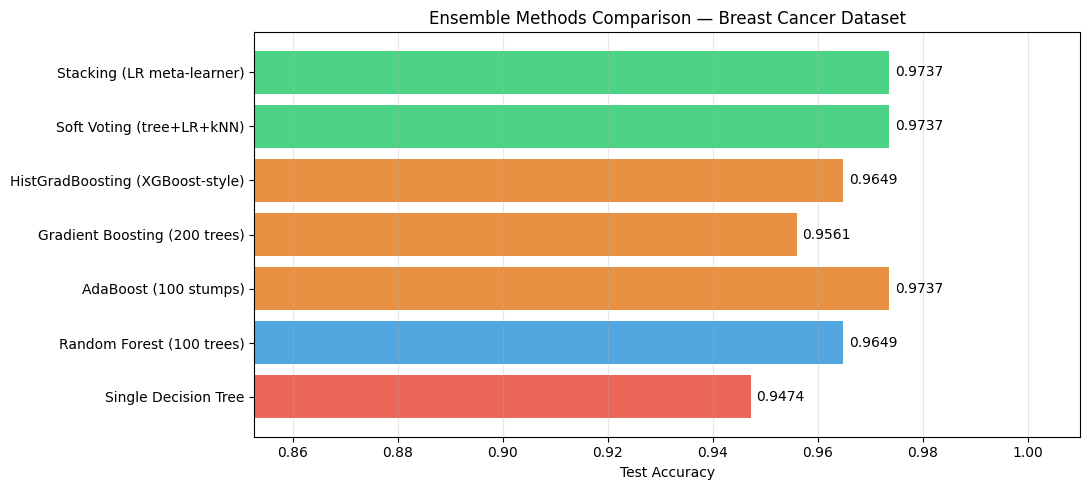


Results (sorted):
  0.9737  AdaBoost (100 stumps)
  0.9737  Soft Voting (tree+LR+kNN)
  0.9737  Stacking (LR meta-learner)
  0.9649  Random Forest (100 trees)
  0.9649  HistGradBoosting (XGBoost-style)
  0.9561  Gradient Boosting (200 trees)
  0.9474  Single Decision Tree


In [46]:
from sklearn.ensemble import StackingClassifier

results = {}

# Baseline
single_tree = DecisionTreeClassifier(random_state=42)
single_tree.fit(X_tr, y_tr)
results['Single Decision Tree'] = accuracy_score(y_te, single_tree.predict(X_te))

# Bagging
results['Random Forest (100 trees)'] = accuracy_score(
    y_te,
    RandomForestClassifier(n_estimators=100, random_state=42).fit(X_tr, y_tr).predict(X_te)
)

# Boosting
results['AdaBoost (100 stumps)'] = accuracy_score(
    y_te,
    AdaBoostClassifier(n_estimators=100, random_state=42).fit(X_tr, y_tr).predict(X_te)
)
results['Gradient Boosting (200 trees)'] = accuracy_score(
    y_te,
    GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, max_depth=3,
                                random_state=42).fit(X_tr, y_tr).predict(X_te)
)
results['HistGradBoosting (XGBoost-style)'] = accuracy_score(
    y_te,
    HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, max_depth=3,
                                    random_state=42).fit(X_tr, y_tr).predict(X_te)
)

# Voting
vc = VotingClassifier(estimators=[
    ('tree', DecisionTreeClassifier(max_depth=5, random_state=42)),
    ('lr',   LogisticRegression(max_iter=1000, random_state=42)),
    ('knn',  KNeighborsClassifier(n_neighbors=5)),
], voting='soft')
vc.fit(X_tr, y_tr)
results['Soft Voting (tree+LR+kNN)'] = accuracy_score(y_te, vc.predict(X_te))

# Stacking
sc = StackingClassifier(
    estimators=[
        ('tree', DecisionTreeClassifier(max_depth=5, random_state=42)),
        ('lr',   LogisticRegression(max_iter=1000, random_state=42)),
        ('knn',  KNeighborsClassifier(n_neighbors=5)),
    ],
    final_estimator=LogisticRegression(max_iter=1000, random_state=42), cv=5
)
sc.fit(X_tr, y_tr)
results['Stacking (LR meta-learner)'] = accuracy_score(y_te, sc.predict(X_te))

# Plot
names = list(results.keys())
accs  = list(results.values())
colors = ['#e74c3c'] + ['#3498db'] * 1 + ['#e67e22'] * 3 + ['#2ecc71'] * 2

plt.figure(figsize=(11, 5))
bars = plt.barh(names, accs, color=colors, alpha=0.85)
plt.xlim(0.9 * min(accs), 1.01)
for bar, acc in zip(bars, accs):
    plt.text(acc + 0.001, bar.get_y() + bar.get_height() / 2,
             f'{acc:.4f}', va='center', fontsize=10)
plt.xlabel('Test Accuracy')
plt.title('Ensemble Methods Comparison \u2014 Breast Cancer Dataset')
plt.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

# Text summary
print("\nResults (sorted):")
for name, acc in sorted(results.items(), key=lambda x: -x[1]):
    print(f"  {acc:.4f}  {name}")

<a id="feature-importance"></a>
## 13. Feature Importance in Random Forest

Random Forest aggregates feature importances across all trees. This gives a more robust estimate than a single decision tree.

**Mean Decrease in Impurity (MDI):**

$$\text{Importance}(j) = \frac{1}{B} \sum_{b=1}^B \sum_{\text{node } v \text{ in tree } b \text{ splitting on } j} \frac{n_v}{n} \cdot \text{Gain}(D_v)$$

**Warning:** MDI can be biased toward high-cardinality features. Use **permutation importance** for a model-agnostic, unbiased estimate:

$$\text{PermImportance}(j) = \text{score}_{\text{baseline}} - \text{score}_{\text{permute column } j}$$

Fit a 200-tree Random Forest on the full training set, then compute both MDI importance (from `feature_importances_`) and permutation importance (30 repeats on the test set) for all 30 breast cancer features.

In [47]:
from sklearn.inspection import permutation_importance

sk_rf_full = RandomForestClassifier(n_estimators=200, random_state=42)
sk_rf_full.fit(X_tr, y_tr)

# MDI importance
mdi_imp = sk_rf_full.feature_importances_

# Permutation importance (on test set)
perm_result = permutation_importance(sk_rf_full, X_te, y_te,
                                      n_repeats=30, random_state=42)
perm_imp    = perm_result.importances_mean

feature_names = cancer.feature_names
top_k = 10  # show only top 10 features

print(f"MDI top feature:         {feature_names[mdi_imp.argmax()]}")
print(f"Permutation top feature: {feature_names[perm_imp.argmax()]}")

MDI top feature:         worst area
Permutation top feature: worst radius


Plot the top-10 features by each method side-by-side (MDI on the left, permutation importance on the right) to highlight any differences in ranking between the two approaches.

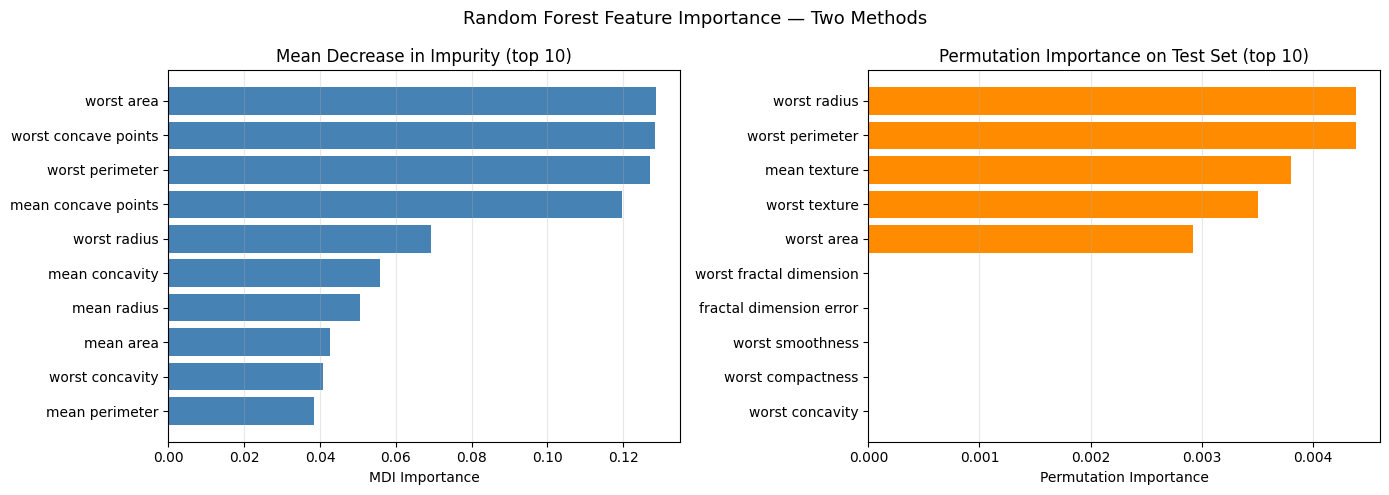

In [48]:
# Sort by MDI
order = np.argsort(mdi_imp)[::-1][:top_k]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].barh(feature_names[order][::-1], mdi_imp[order][::-1], color='steelblue')
axes[0].set_xlabel('MDI Importance')
axes[0].set_title('Mean Decrease in Impurity (top 10)')
axes[0].grid(True, alpha=0.3, axis='x')

order_perm = np.argsort(perm_imp)[::-1][:top_k]
axes[1].barh(feature_names[order_perm][::-1], perm_imp[order_perm][::-1], color='darkorange')
axes[1].set_xlabel('Permutation Importance')
axes[1].set_title('Permutation Importance on Test Set (top 10)')
axes[1].grid(True, alpha=0.3, axis='x')

plt.suptitle('Random Forest Feature Importance \u2014 Two Methods', fontsize=13)
plt.tight_layout()
plt.show()

<a id="summary"></a>
## 14. Summary

### What we covered

```
Ensemble Methods
\u2502
\u251c\u2500\u2500 Bagging  \u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500 Reduces variance
\u2502   \u251c\u2500\u2500 Bootstrap: sample n with replacement \u2192 ~63.2% unique
\u2502   \u251c\u2500\u2500 OOB: free validation on left-out 36.8%
\u2502   \u2514\u2500\u2500 Random Forest = Bagging + random feature subsets (\u221ap)
\u2502
\u251c\u2500\u2500 Boosting  \u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500 Reduces bias
\u2502   \u251c\u2500\u2500 AdaBoost
\u2502   \u2502   \u251c\u2500\u2500 Reweight misclassified samples each round
\u2502   \u2502   \u251c\u2500\u2500 \u03b1_t = \u00bd ln((1-\u03b5_t)/\u03b5_t)  \u2014 learner weight
\u2502   \u2502   \u2514\u2500\u2500 Final: sign(\u03a3 \u03b1_t h_t(x))
\u2502   \u251c\u2500\u2500 Gradient Boosting
\u2502   \u2502   \u251c\u2500\u2500 Fit trees to pseudo-residuals = -dL/dF
\u2502   \u2502   \u251c\u2500\u2500 F_t = F_{t-1} + \u03b7 * h_t(x)
\u2502   \u2502   \u2514\u2500\u2500 Lower \u03b7 \u2192 more trees \u2192 better generalization
\u2502   \u2514\u2500\u2500 XGBoost: 2nd-order gradients + regularization + \u2113\u2082 leaf penalty
\u2502
\u2514\u2500\u2500 Voting / Stacking  \u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500 Combines heterogeneous models
    \u251c\u2500\u2500 Hard voting: majority class
    \u251c\u2500\u2500 Soft voting: average class probabilities (usually better)
    \u2514\u2500\u2500 Stacking: meta-learner trained on OOF base predictions
```

### Practical guide: which method to use?

| Situation | Recommended |
|---|---|
| Need interpretability | Single decision tree |
| Tabular data, maximize accuracy | XGBoost / LightGBM |
| Need fast training + good accuracy | Random Forest |
| Very noisy data | Random Forest (robust to outliers) |
| Very small dataset | Bagging (OOB avoids wasting data on validation) |
| Have heterogeneous model types | Soft Voting or Stacking |
| Competition / maximize last % | Stacking |

**Key rule:** Gradient Boosting (XGBoost/LightGBM/CatBoost) wins most tabular benchmarks. Random Forest is the go-to for robust, low-tuning baselines.

<a id="sources"></a>
## 15. Sources

### Foundational Papers
- **Breiman, L. (1996)**. Bagging Predictors. *Machine Learning*, 24(2), 123–140. — Introduced bootstrap aggregating. [DOI](https://doi.org/10.1007/BF00058655)
- **Breiman, L. (2001)**. Random Forests. *Machine Learning*, 45(1), 5–32. — Original Random Forest paper. [DOI](https://doi.org/10.1023/A:1010933404324)
- **Geurts, P., Ernst, D. & Wehenkel, L. (2006)**. Extremely randomized trees. *Machine Learning*, 63(1), 3–42. — Extra Trees. [DOI](https://doi.org/10.1007/s10994-006-6226-1)
- **Schapire, R.E. (1990)**. The Strength of Weak Learnability. *Machine Learning*, 5(2), 197–227. — Theoretical foundation of boosting.
- **Freund, Y. & Schapire, R.E. (1997)**. A Decision-Theoretic Generalization of On-Line Learning and an Application to Boosting. *JCSS*, 55(1), 119–139. — AdaBoost. [DOI](https://doi.org/10.1006/jcss.1997.1504)
- **Friedman, J.H. (2001)**. Greedy Function Approximation: A Gradient Boosting Machine. *Annals of Statistics*, 29(5), 1189–1232. — Original Gradient Boosting. [Link](https://projecteuclid.org/euclid.aos/1013203451)
- **Chen, T. & Guestrin, C. (2016)**. XGBoost: A Scalable Tree Boosting System. *KDD 2016*. — XGBoost. [arXiv](https://arxiv.org/abs/1603.02754)

### Textbooks
- James, Witten, Hastie, Tibshirani. ***An Introduction to Statistical Learning***. Chapter 8: Tree-Based Methods (Bagging, RF, Boosting). [Free PDF](https://www.statlearning.com/)
- Hastie, Tibshirani, Friedman. ***The Elements of Statistical Learning***. Chapter 10: Boosting and Additive Trees. [Free PDF](https://web.stanford.edu/~hastie/ElemStatLearn/)

### Online Resources
- [scikit-learn — Ensemble Methods](https://scikit-learn.org/stable/modules/ensemble.html)
- [XGBoost Documentation — Algorithm Details](https://xgboost.readthedocs.io/en/stable/tutorials/model.html)
- [Wikipedia — Random Forest](https://en.wikipedia.org/wiki/Random_forest)
- [Wikipedia — Gradient Boosting](https://en.wikipedia.org/wiki/Gradient_boosting)
- [Wikipedia — AdaBoost](https://en.wikipedia.org/wiki/AdaBoost)
- [Wikipedia — Bootstrap Aggregating](https://en.wikipedia.org/wiki/Bootstrap_aggregating)